In [1]:
from auxillaryFunctions import *
np.random.seed(0)

STNchannels = np.load(r"tools\translatedSTNchannels2.npy",allow_pickle=True).item()
GPechannels = np.load(r"tools\translatedGPechannels2.npy",allow_pickle=True).item()
STNbias = -2.1
GPeBias = -0.23

TS = 0.04
simScale = 10
k = 10
nSTN,nGPe,nIdk = simScale,3*simScale,0
nCTX,nMSN = 10*simScale, 30*simScale
CTXrate,MSNrate = 3.3,2.1 #3.3,2.1
nSTN_GPe,nGPe_GPe,nGPe_STN,nCTX_STN,nMSN_GPe = k*nSTN,k*nGPe,k*nGPe,k*nSTN,k*nGPe


coupling,nSegments = 0.25,2 #2 segments gives 3 total segments including soma
STNDendriteMap = [(i+1,0,coupling) for i in range(nSegments)]
STNDendriteInfo = [{"channels":STNchannels,"bias":STNbias,"CaEquilibriumVal":0,
                            "CaRemovalRate":2} for _ in range(nSegments)]

STNNeurons = [Neuron(i,"STN","excitatory",AISchannels=STNchannels,AISbias=STNbias,denderiteInfo=STNDendriteInfo,dendriteMap=STNDendriteMap) for i in range(nSTN)]
GPeNeurons = [Neuron(i,"GPe","inhibitory",AISchannels=GPechannels,AISbias=GPeBias) for i in range(nGPe)]

CTXSpikers = [Spiker(i,"CTX","excitatory",CTXrate,TS) for i in range(nCTX)]
MSNSpikers = [Spiker(i,"MSN","inhibitory",MSNrate,TS) for i in range(nMSN)]

neuronDict = {"STN":STNNeurons,"GPe":GPeNeurons}
spikerDict = {"CTX":CTXSpikers,"MSN":MSNSpikers}

CTXToSTNSynapses = createSynapses(CTXSpikers,STNNeurons,nCTX_STN,0.015,0.2,TS)
STNToGPeSynapses = createSynapses(STNNeurons,GPeNeurons,nSTN_GPe,0.015,4,TS) #
GPeToSTNSynapses = createSynapses(GPeNeurons,STNNeurons,nGPe_STN,0.5,4,TS)
GPeToGPeSynapses = createSynapses(GPeNeurons,GPeNeurons,nGPe_GPe,0.025,4,TS)
MSNToGPeSynapses = createSynapses(MSNSpikers,GPeNeurons,nGPe_GPe,0.02,0.2,TS)

synapseDict = {"CTXToSTN":CTXToSTNSynapses,"STNToGPe":STNToGPeSynapses,"GPeToSTN":GPeToSTNSynapses,
                "GPeToGPe":GPeToGPeSynapses,"MSNToGPe":MSNToGPeSynapses}


simData,connectionToChannelMap = genSimData(neuronDict,spikerDict,synapseDict,TS)
print(f"Total number of channels {simData['nChannels']}")

Total number of channels 1860


In [2]:
stimInfoSpikes = {}
syns = [i for i,n in enumerate(simData["name"]) if n == "AMPAR"] #"AMPAR" #GABA
#stimSynapse(stimInfoSpikes,syns,50,100,TS

runTime = 100
stimInfoCurrents = {} 

simDataPy = deepcopy(simData)
simDataPy["debugRecording"] = np.zeros_like(simDataPy["current"])

data = solveSystemStandard(simDataPy,TS,runTime,stimInfoSpikes,stimInfoCurrents,vectorized=True,nSamples=None, useTQDM=True,
                           recordingKeys = ["voltages","calciumVals","netCurrent","x","debugRecording","CaChannelCurrent","spikerOutput"])

#TODO: add spike recording to cpp side

  0%|          | 0/2500 [00:00<?, ?it/s]

c:\Users\CathalMcLoughlin\Documents\GitHub\pythonCPPtesting.ipynb\auxillaryFunctions.py:50: RuntimeWarning: overflow encountered in exp
  return minOp +  (1.0-minOp)/(1.0 + np.exp((h-z)*kInv))
100%|██████████| 2500/2500 [00:04<00:00, 624.05it/s]


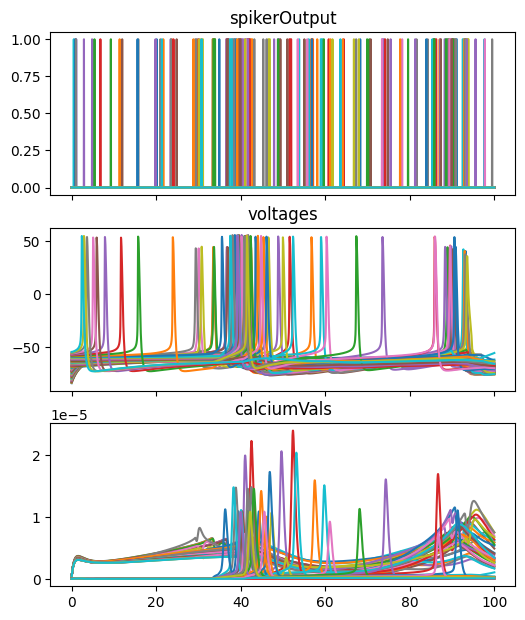

In [3]:
keysToPlot = ["spikerOutput","voltages","calciumVals","time"]
standardPlot({key:data[key] for key in keysToPlot})

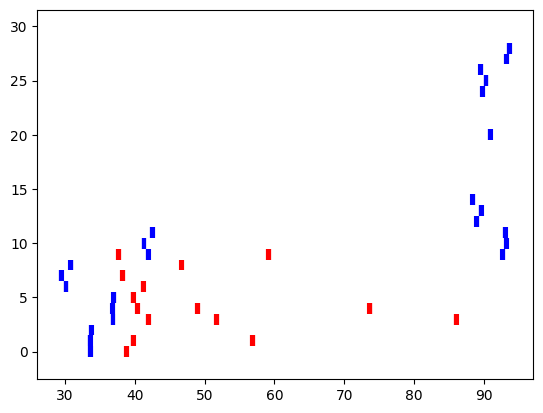

In [4]:
def getPopSpikeTrains(simDataPy,data):
    #NOTE: as of 28/11 this doesnt work. It actually never worked, it only worked when each neuron had 1 segment. Now that this is not the case I need to fix it
    neuronToSpiker = {}
    for i,val in enumerate(simDataPy["spikerPreNeuron"]):
        if val not in neuronToSpiker.keys():
            neuronToSpiker[i] = int(val)

    neuronPopToSpiker = {}
    spikerToPop = {}

    for i,name in enumerate(simDataPy["neuronName"]):
        if name not in neuronPopToSpiker:
            neuronPopToSpiker[name] = []
        neuronPopToSpiker[name].append(i)
        spikerToPop[i] = name

    #spikes = data["spikerOutput"][:,neuronPopToSpiker["GPe"][1]]
    nNeurons = simDataPy["nNeuralSpikers"]
    spikeTimes = [[] for i in range(nNeurons)]
    for timeInd,neurInd in zip(*np.where(data["spikerOutput"][:,0:nNeurons]==1)):
        spikeTimes[neurInd].append(float(data["time"][timeInd]))

    popSpikeTrains = {k:[] for k in neuronPopToSpiker.keys()}
    for i,trains in enumerate(spikeTimes):
        popSpikeTrains[spikerToPop[i]].append(trains)
    return popSpikeTrains

popSpikeTrains = getPopSpikeTrains(simDataPy,data)
fig,ax = plt.subplots(1,1)
ax.eventplot(popSpikeTrains["STN"],color="b");
ax.eventplot(popSpikeTrains["GPe"],color="r");

In [5]:
simDataPy["nNeuralSpikers"]

40

In [9]:
spikeRates = {}
for i,train in enumerate(popSpikeTrains["STN"]):
    anySpike = len(train)>0
    ISI = np.diff(train)
    ISIoverThresh = sum(ISI>1.0)
    nSpikes = anySpike+ISIoverThresh
    spikeRates[i] = int(nSpikes)*1000/runTime

spikeRates

{0: 10.0,
 1: 10.0,
 2: 10.0,
 3: 10.0,
 4: 10.0,
 5: 10.0,
 6: 10.0,
 7: 10.0,
 8: 10.0,
 9: 20.0,
 10: 20.0,
 11: 20.0,
 12: 10.0,
 13: 10.0,
 14: 10.0,
 15: 0.0,
 16: 0.0,
 17: 0.0,
 18: 0.0,
 19: 0.0,
 20: 10.0,
 21: 0.0,
 22: 0.0,
 23: 0.0,
 24: 10.0,
 25: 10.0,
 26: 10.0,
 27: 10.0,
 28: 10.0,
 29: 0.0}

In [4]:
simDataPy["spikeTrains"]; #NOTE: I dont like this philosophy of this and it sholud be removed later. Keep state and recording data separate 


In [ ]:
build_dir,configType = "build", "Release" #"Debug" Release ##NOTE: make sure your are using correct version
moduleDir = os.path.join(build_dir, configType)
if moduleDir not in sys.path:
    sys.path.append(moduleDir)

import cathalTest

    
def solveSystemCpp(ac,TS,runTime,samplingInterval=2,stimInfoSpikes={},stimInfoCurrents = {}, recordingKeys = ["voltages","calciumVals","netCurrent","current"]):
    nIterations = int(runTime/TS)
    nSamples = int(np.ceil(nIterations/samplingInterval))
    spikeStimTimes,spikeStimNeurons = genSpikeStimArrays(stimInfoSpikes)
    ac["spikeStimTimes"] = spikeStimTimes
    ac["spikeStimNeurons"] = spikeStimNeurons

    biasStimTimes,biasStimSegments,biasStimValues = genBiasStimArrays(stimInfoCurrents)
    ac["biasStimTimes"] = biasStimTimes
    ac["biasStimSegments"] = biasStimSegments
    ac["biasStimValues"] = biasStimValues
    ac["performanceStats"] = np.zeros(8,dtype=np.float32)


    recordingData = {}
    for key in recordingKeys:
        shape = [nSamples] + list(ac[key].shape)
        recordingData[key] = np.zeros(shape,dtype=np.float32) #np.ascontiguousarray

    tv = np.linspace(0,runTime,nSamples)
    print("here")
    cathalTest.solveNeuralSystem(ac,recordingData,TS,nIterations,samplingInterval)

    #trackPerfOverTime(ac)

    recordingData["time"] = tv
    return recordingData


simDataPy = deepcopy(simData)
stimInfoSpikes,stimInfoCurrents = {},{}
allChannelDataCpp = deepcopy(simData)
allChannelDataCpp["debugRecording"] = np.zeros_like(simDataPy["current"])
dataCpp = solveSystemCpp(allChannelDataCpp,TS,runTime,samplingInterval=4,stimInfoSpikes=stimInfoSpikes,
                         recordingKeys = ["voltages","calciumVals","current"])

